# Fase 2 — Entendimento dos Dados

**Projeto:** Mapa de Calor e Predição do Risco de Acidentes de Trânsito na BR-230

Nesta fase examinamos os registros públicos de acidentes da Polícia Rodoviária Federal (PRF) que vamos usar no mapa de calor e na estimativa de risco da BR-230. O tema, a rodovia e a fonte já foram definidos no entendimento do negócio.

Organizamos o exame nas quatro tarefas de entendimento dos dados do CRISP-DM:

1. **Coleta inicial** — de onde vieram os arquivos e como os carregamos.
2. **Descrição** — formato, volume, campos, grão e propriedades de superfície.
3. **Exploração** — distribuições, relações e agregações ligadas aos objetivos do projeto.
4. **Qualidade** — completude, erros, valores ausentes e o que encaminhamos para a preparação.


## 1. Perguntas da exploração

O tema e a base já estão definidos. Para manter o exame ligado ao que o projeto precisa responder, partimos de cinco perguntas.

1. Os arquivos de 2025 da PRF trazem a BR-230 com localização suficiente para representar os acidentes no espaço?
2. Em quais estados, municípios e trechos as ocorrências se concentram?
3. Em quais horários, dias, condições de via e condições meteorológicas as ocorrências e os desfechos graves são mais frequentes?
4. Qual arquivo alimenta o mapa, qual descreve as pessoas e qual descreve causas e tipos adicionais?
5. A base distingue um trecho com muitos acidentes de um trecho em que o acidente tende a ser mais grave?

A quinta pergunta separa dois resultados que vamos manter distintos daqui em diante. A **concentração histórica** alimenta o mapa de calor. A **gravidade do acidente já ocorrido** é o desfecho que esta base permite observar.


## 2. Leitura dos arquivos

Lemos os CSV da PRF com Pandas, com separador ponto e vírgula, vírgula decimal e codificação ISO-8859-1. Com esse ajuste, latitude e longitude entram como número e os nomes acentuados são preservados. Os arquivos estão na pasta `bases/`, e a leitura funciona com o arquivo aberto em `entendimento_dados/` ou na raiz do projeto.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 140)

plt.rcParams.update({
    "figure.figsize": (11, 4.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 13,
})


def localizar_bases() -> Path:
    candidatos = [Path.cwd() / "bases", Path.cwd().parent / "bases"]
    for caminho in candidatos:
        if (caminho / "datatran2025.csv").exists():
            return caminho.resolve()
    raise FileNotFoundError(
        "A pasta bases/ não foi encontrada. Abra o notebook na raiz do projeto ou em entendimento_dados/."
    )


def ler_prf(nome: str, **kwargs) -> pd.DataFrame:
    return pd.read_csv(
        BASES / nome,
        sep=";",
        decimal=",",
        encoding="latin-1",
        low_memory=False,
        **kwargs,
    )


BASES = localizar_bases()
BASES


PosixPath('/Users/jbassneto/Documents/projects/CienciaDados/bases')

## 3. Coleta inicial dos dados

Usamos os dados abertos de acidentes da PRF, a fonte definida na fase de negócio. O portal publica três extrações de 2025, com grãos diferentes. As três estão na pasta `bases/` e formam o catálogo abaixo. O período coberto pelos arquivos é o ano civil de 2025. Anos anteriores ainda ficam de fora desta pasta.

Na carga, tratamos três características do arquivo:

- a codificação é ISO-8859-1;
- o separador é `;` e o decimal é `,`, então uma latitude como `-7,12` entra como número;
- o arquivo de todas as causas e tipos repete o mesmo acidente em várias linhas, e por isso o lemos em blocos, separando o volume de linhas do volume de acidentes.


In [3]:
catalogo = pd.DataFrame(
    [
        {
            "arquivo": "datatran2025.csv",
            "nome": "Acidentes 2025 agrupados por ocorrência",
            "grao": "1 linha = 1 acidente",
            "uso_no_projeto": "Mapa de calor, contagem de ocorrências e gravidade do acidente",
            "origem": "Dados abertos da PRF: agrupados por ocorrência",
        },
        {
            "arquivo": "acidentes2025.csv",
            "nome": "Acidentes 2025 agrupados por pessoa",
            "grao": "1 linha = 1 pessoa envolvida",
            "uso_no_projeto": "Perfil de vítimas, veículos e estado físico",
            "origem": "Dados abertos da PRF: agrupados por pessoa",
        },
        {
            "arquivo": "acidentes2025_todas_causas_tipos.csv",
            "nome": "Acidentes 2025 por pessoa, com todas as causas e tipos",
            "grao": "1 linha = 1 pessoa × causa × tipo",
            "uso_no_projeto": "Causas e tipos além do registro principal",
            "origem": "Dados abertos da PRF: todas as causas e tipos",
        },
    ]
)

catalogo["bytes"] = catalogo["arquivo"].map(lambda nome: (BASES / nome).stat().st_size)
catalogo["tamanho_mb"] = (catalogo["bytes"] / 1024**2).round(1)
catalogo


,arquivo,nome,grao,uso_no_projeto,origem,bytes,tamanho_mb
0,datatran2025.csv,Acidentes 2025 agrupados por ocorrência,1 linha = 1 acidente,"Mapa de calor, contagem de ocorrências e gravi...",Dados abertos da PRF: agrupados por ocorrência,21143436,20.2
1,acidentes2025.csv,Acidentes 2025 agrupados por pessoa,1 linha = 1 pessoa envolvida,"Perfil de vítimas, veículos e estado físico",Dados abertos da PRF: agrupados por pessoa,72881148,69.5
2,acidentes2025_todas_causas_tipos.csv,"Acidentes 2025 por pessoa, com todas as causas...",1 linha = 1 pessoa × causa × tipo,Causas e tipos além do registro principal,Dados abertos da PRF: todas as causas e tipos,223019483,212.7


In [4]:
ocorrencias = ler_prf("datatran2025.csv")
pessoas = ler_prf("acidentes2025.csv")

colunas_expandidas = None
nulos_expandidos = None
linhas_expandidas = 0
ids_expandidos = set()
partes_br = []
colunas_br = [
    "id",
    "pesid",
    "causa_principal",
    "causa_acidente",
    "ordem_tipo_acidente",
    "tipo_acidente",
    "br",
    "uf",
]

for bloco in ler_prf("acidentes2025_todas_causas_tipos.csv", chunksize=200_000):
    linhas_expandidas += len(bloco)
    ids_expandidos.update(bloco["id"].dropna().astype("int64"))
    if colunas_expandidas is None:
        colunas_expandidas = list(bloco.columns)
        nulos_expandidos = bloco.isna().sum()
    else:
        nulos_expandidos = nulos_expandidos.add(bloco.isna().sum(), fill_value=0)
    partes_br.append(bloco.loc[bloco["br"].eq(230), colunas_br])

expandidos_br = pd.concat(partes_br, ignore_index=True)

print(f"Ocorrências: {ocorrencias.shape[0]:,} linhas × {ocorrencias.shape[1]} colunas")
print(f"Pessoas:     {pessoas.shape[0]:,} linhas × {pessoas.shape[1]} colunas")
print(f"Expandido:   {linhas_expandidas:,} linhas × {len(colunas_expandidas)} colunas")
print(f"Acidentes distintos no arquivo expandido: {len(ids_expandidos):,}")
print(f"Linhas do arquivo expandido na BR-230: {len(expandidos_br):,}")


Ocorrências: 72,529 linhas × 30 colunas
Pessoas:     194,629 linhas × 35 colunas
Expandido:   584,010 linhas × 37 colunas
Acidentes distintos no arquivo expandido: 72,529
Linhas do arquivo expandido na BR-230: 18,255


## 4. Descrição dos dados

Descrevemos o formato, a quantidade de registros, a identidade dos campos e as demais propriedades de superfície. Em seguida, confrontamos o que foi coletado com o que o projeto precisa: localização, tempo, via, meteorologia e um desfecho capaz de representar gravidade.

### 4.1 Embalagem

Conferimos o número de linhas, o número de colunas e o tipo de cada campo logo depois da leitura. Um número lido como texto, ou uma data lida como número, alteraria todas as contas seguintes.


In [5]:
def embalagem(nome, dados, linhas=None, colunas=None):
    linhas = len(dados) if linhas is None else linhas
    colunas = dados.shape[1] if colunas is None else colunas
    return {
        "arquivo": nome,
        "linhas": linhas,
        "colunas": colunas,
        "ids": dados["id"].nunique() if "id" in dados.columns else len(ids_expandidos),
        "memoria_mb": round(dados.memory_usage(deep=True).sum() / 1024**2, 1),
    }


resumo_embalagem = pd.DataFrame(
    [
        embalagem("datatran2025.csv", ocorrencias),
        embalagem("acidentes2025.csv", pessoas),
        {
            "arquivo": "acidentes2025_todas_causas_tipos.csv",
            "linhas": linhas_expandidas,
            "colunas": len(colunas_expandidas),
            "ids": len(ids_expandidos),
            "memoria_mb": None,
        },
    ]
)
resumo_embalagem


,arquivo,linhas,colunas,ids,memoria_mb
0,datatran2025.csv,72529,30,72529,82.5
1,acidentes2025.csv,194629,35,72529,279.3
2,acidentes2025_todas_causas_tipos.csv,584010,37,72529,NaN


In [6]:
print("Tipos: arquivo por ocorrência")
print(ocorrencias.dtypes.to_string())
print("\nTipos: arquivo por pessoa (colunas que só existem neste grão)")
colunas_so_pessoa = [coluna for coluna in pessoas.columns if coluna not in ocorrencias.columns]
print(pessoas[colunas_so_pessoa].dtypes.to_string())
print("\nColunas exclusivas do arquivo expandido:")
print([coluna for coluna in colunas_expandidas if coluna not in pessoas.columns])


Tipos: arquivo por ocorrência
id                          int64
data_inversa                  str
dia_semana                    str
horario                       str
uf                            str
br                          int64
km                        float64
municipio                     str
causa_acidente                str
tipo_acidente                 str
classificacao_acidente        str
fase_dia                      str
sentido_via                   str
condicao_metereologica        str
tipo_pista                    str
tracado_via                   str
uso_solo                      str
pessoas                     int64
mortos                      int64
feridos_leves               int64
feridos_graves              int64
ilesos                      int64
ignorados                   int64
feridos                     int64
veiculos                    int64
latitude                  float64
longitude                 float64
regional                      str
delegacia         

### 4.2 Início e fim da base

As primeiras e as últimas linhas mostram se a leitura chegou ao fim do arquivo e se o período corresponde a 2025. Nas tabelas abaixo ficam as colunas que identificam o acidente no tempo e no espaço. A lista completa dos campos vem no dicionário.


In [7]:
colunas_visita = [
    "id",
    "data_inversa",
    "horario",
    "dia_semana",
    "uf",
    "br",
    "km",
    "municipio",
    "classificacao_acidente",
    "latitude",
    "longitude",
]

print("Período:", ocorrencias["data_inversa"].min(), "a", ocorrencias["data_inversa"].max())
print("\nPrimeiras ocorrências")
display(ocorrencias[colunas_visita].head(5))
print("Últimas ocorrências")
display(ocorrencias[colunas_visita].tail(5))


Período: 2025-01-01 a 2025-12-31

Primeiras ocorrências


,id,data_inversa,horario,dia_semana,uf,br,km,municipio,classificacao_acidente,latitude,longitude
0,652493,2025-01-01,06:20:00,quarta-feira,SP,116,225.0,GUARULHOS,Com Vítimas Feridas,-23.485868,-46.540753
1,652519,2025-01-01,07:50:00,quarta-feira,CE,116,546.2,PENAFORTE,NaN,-7.812288,-39.083333
2,652522,2025-01-01,08:45:00,quarta-feira,PR,369,88.2,CORNELIO PROCOPIO,Com Vítimas Feridas,-23.182565,-50.637228
3,652544,2025-01-01,11:00:00,quarta-feira,PR,116,74.0,CAMPINA GRANDE DO SUL,Com Vítimas Feridas,-25.365177,-49.042230
4,652549,2025-01-01,09:30:00,quarta-feira,MG,251,471.0,FRANCISCO SA,Com Vítimas Feridas,-16.468013,-43.431213


Últimas ocorrências


,id,data_inversa,horario,dia_semana,uf,br,km,municipio,classificacao_acidente,latitude,longitude
72524,757462,2025-12-20,13:10:00,sábado,MG,381,279.5,JAGUARACU,Com Vítimas Feridas,-19.607000,-42.761100
72525,757492,2025-09-27,13:50:00,sábado,SC,282,381.0,HERVAL DOESTE,Com Vítimas Feridas,-27.209600,-51.500770
72526,757593,2025-12-14,13:50:00,domingo,PE,104,62.0,CARUARU,Com Vítimas Feridas,-8.253680,-35.975460
72527,758175,2025-12-15,15:50:00,segunda-feira,SC,101,130.0,CAMBORIU,Sem Vítimas,-26.993060,-48.660955
72528,758186,2025-11-02,23:00:00,domingo,MG,381,218.3,BELO ORIENTE,Com Vítimas Feridas,-19.298811,-42.371921


### 4.3 Dicionário de dados

O dicionário descreve cada campo no arquivo por ocorrência, que é o grão do mapa. Quatro particularidades mudam a leitura dos outros arquivos:

- No arquivo por pessoa, `ilesos`, `feridos_leves`, `feridos_graves` e `mortos` são indicadores 0/1 daquela pessoa. A soma desses indicadores por `id` reconstrói a contagem da ocorrência.
- `tracado_via` pode trazer mais de um valor na mesma célula, separado por ponto e vírgula (`Reta;Declive`).
- `uso_solo = Sim` indica área urbana; `Não` indica área rural, na codificação da PRF.
- `sentido_via` segue a quilometragem da rodovia: crescente ou decrescente.

A descrição acompanha o dicionário publicado pela PRF para as extrações a partir de 2017: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes>.


In [8]:
dicionario = pd.DataFrame(
    [
        ("id", "Identificador do acidente", "Ocorrência e pessoa"),
        ("pesid", "Identificador da pessoa. O valor 0 reúne pessoas sem identificação.", "Pessoa"),
        ("data_inversa", "Data do acidente, no formato aaaa-mm-dd.", "Ocorrência"),
        ("dia_semana", "Dia da semana por extenso.", "Ocorrência"),
        ("horario", "Hora do acidente, no formato hh:mm:ss.", "Ocorrência"),
        ("uf", "Unidade da federação do local do acidente.", "Ocorrência"),
        ("br", "Número da rodovia federal.", "Ocorrência"),
        ("km", "Quilômetro da rodovia. A marcação recomeça em cada UF.", "Ocorrência"),
        ("municipio", "Município do local do acidente.", "Ocorrência"),
        ("causa_acidente", "Causa registrada. No arquivo por ocorrência, é a causa principal.", "Ocorrência"),
        ("tipo_acidente", "Tipo registrado. No arquivo por ocorrência, é o tipo de ordem 1.", "Ocorrência"),
        ("classificacao_acidente", "Sem Vítimas, Com Vítimas Feridas ou Com Vítimas Fatais.", "Ocorrência"),
        ("fase_dia", "Pleno dia, Amanhecer, Anoitecer ou Plena Noite.", "Ocorrência"),
        ("sentido_via", "Crescente, Decrescente ou Não Informado.", "Ocorrência"),
        ("condicao_metereologica", "Condição meteorológica informada no registro do acidente.", "Ocorrência"),
        ("tipo_pista", "Simples, Dupla ou Múltipla.", "Ocorrência"),
        ("tracado_via", "Geometria da via. Pode haver mais de um valor na mesma célula.", "Ocorrência"),
        ("uso_solo", "Sim: área urbana. Não: área rural.", "Ocorrência"),
        ("pessoas", "Quantidade de pessoas envolvidas no acidente.", "Ocorrência"),
        ("mortos", "Na ocorrência, quantidade de mortos. Na pessoa, indicador 0/1 de óbito.", "Os dois, com significado diferente"),
        ("feridos_leves", "Na ocorrência, contagem. Na pessoa, indicador 0/1 de lesão leve.", "Os dois, com significado diferente"),
        ("feridos_graves", "Na ocorrência, contagem. Na pessoa, indicador 0/1 de lesão grave.", "Os dois, com significado diferente"),
        ("ilesos", "Na ocorrência, contagem. Na pessoa, indicador 0/1 de ileso.", "Os dois, com significado diferente"),
        ("ignorados", "Pessoas com estado físico ignorado. Só existe no arquivo por ocorrência.", "Ocorrência"),
        ("feridos", "Soma de feridos leves e graves.", "Ocorrência"),
        ("veiculos", "Quantidade de veículos envolvidos.", "Ocorrência"),
        ("latitude", "Latitude em graus decimais.", "Ocorrência"),
        ("longitude", "Longitude em graus decimais.", "Ocorrência"),
        ("regional", "Superintendência da PRF responsável pelo registro.", "Ocorrência"),
        ("delegacia", "Delegacia da PRF.", "Ocorrência"),
        ("uop", "Unidade operacional da PRF.", "Ocorrência"),
        ("id_veiculo", "Identificador do veículo da pessoa.", "Pessoa"),
        ("tipo_veiculo", "Tipo do veículo.", "Pessoa"),
        ("marca", "Marca do veículo.", "Pessoa"),
        ("ano_fabricacao_veiculo", "Ano de fabricação. O valor 0 funciona como ausência.", "Pessoa"),
        ("tipo_envolvido", "Condutor, passageiro, pedestre, testemunha ou outro.", "Pessoa"),
        ("estado_fisico", "Ileso, lesões leves, lesões graves, óbito ou não informado.", "Pessoa"),
        ("idade", "Idade informada. O valor 0 mistura ausência e idade não positiva.", "Pessoa"),
        ("sexo", "Sexo informado.", "Pessoa"),
        ("causa_principal", "Sim ou Não. Indica se aquela linha é a causa principal.", "Arquivo expandido"),
        ("ordem_tipo_acidente", "Ordem do tipo de acidente naquela linha, a partir de 1.", "Arquivo expandido"),
    ],
    columns=["campo", "descricao", "arquivo"],
)

dicionario


,campo,descricao,arquivo
0,id,Identificador do acidente,Ocorrência e pessoa
1,pesid,Identificador da pessoa. O valor 0 reúne pesso...,Pessoa
2,data_inversa,"Data do acidente, no formato aaaa-mm-dd.",Ocorrência
3,dia_semana,Dia da semana por extenso.,Ocorrência
4,horario,"Hora do acidente, no formato hh:mm:ss.",Ocorrência
...,...,...,...
36,estado_fisico,"Ileso, lesões leves, lesões graves, óbito ou n...",Pessoa
37,idade,Idade informada. O valor 0 mistura ausência e ...,Pessoa
38,sexo,Sexo informado.,Pessoa
39,causa_principal,Sim ou Não. Indica se aquela linha é a causa p...,Arquivo expandido


### 4.4 Grão e relação entre os três arquivos

Os três CSV saem do mesmo sistema de boletins. Compartilham os mesmos acidentes e diferem pela repetição da linha. Uma contagem no arquivo errado multiplica os acidentes da BR-230 e distorce o mapa.

Conferimos três pontos: se os identificadores de acidente coincidem, quantas linhas o arquivo por pessoa tem por acidente e se o arquivo expandido volta ao grão de pessoa quando mantemos a causa principal e o tipo de ordem 1.


In [9]:
ids_ocorrencia = set(ocorrencias["id"])
ids_pessoa = set(pessoas["id"])

conciliacao = pd.DataFrame(
    [
        {
            "conferencia": "Acidentes no arquivo por ocorrência",
            "valor": ocorrencias["id"].nunique(),
        },
        {
            "conferencia": "Acidentes no arquivo por pessoa",
            "valor": pessoas["id"].nunique(),
        },
        {
            "conferencia": "Acidentes no arquivo expandido",
            "valor": len(ids_expandidos),
        },
        {
            "conferencia": "Identificadores só na ocorrência",
            "valor": len(ids_ocorrencia - ids_pessoa),
        },
        {
            "conferencia": "Identificadores só na pessoa",
            "valor": len(ids_pessoa - ids_ocorrencia),
        },
        {
            "conferencia": "Identificadores só no expandido",
            "valor": len(ids_expandidos - ids_ocorrencia),
        },
        {
            "conferencia": "Linhas de pessoa por acidente (média)",
            "valor": round(len(pessoas) / pessoas["id"].nunique(), 2),
        },
        {
            "conferencia": "Linhas expandidas por acidente (média)",
            "valor": round(linhas_expandidas / len(ids_expandidos), 2),
        },
    ]
)
conciliacao


,conferencia,valor
0,Acidentes no arquivo por ocorrência,72529.00
1,Acidentes no arquivo por pessoa,72529.00
2,Acidentes no arquivo expandido,72529.00
3,Identificadores só na ocorrência,0.00
4,Identificadores só na pessoa,0.00
5,Identificadores só no expandido,0.00
6,Linhas de pessoa por acidente (média),2.68
7,Linhas expandidas por acidente (média),8.05


In [10]:
principal = expandidos_br[
    expandidos_br["causa_principal"].eq("Sim") & expandidos_br["ordem_tipo_acidente"].eq(1)
]
pessoas_br_ids = pessoas.loc[pessoas["br"].eq(230), "id"]

print(f"Linhas expandidas na BR-230: {len(expandidos_br):,}")
print(f"Acidentes distintos nessas linhas: {expandidos_br['id'].nunique():,}")
print(f"Linhas com causa principal e tipo de ordem 1: {len(principal):,}")
print(f"Linhas do arquivo por pessoa na BR-230: {pessoas_br_ids.shape[0]:,}")
print(
    "Acidentes com mais de uma causa na BR-230: "
    f"{(expandidos_br.groupby('id')['causa_acidente'].nunique() > 1).mean():.1%}"
)
print(
    "Acidentes com mais de um tipo na BR-230: "
    f"{(expandidos_br.groupby('id')['tipo_acidente'].nunique() > 1).mean():.1%}"
)


Linhas expandidas na BR-230: 18,255
Acidentes distintos nessas linhas: 1,745
Linhas com causa principal e tipo de ordem 1: 4,410
Linhas do arquivo por pessoa na BR-230: 4,410
Acidentes com mais de uma causa na BR-230: 42.5%
Acidentes com mais de um tipo na BR-230: 65.5%


Os três arquivos descrevem os mesmos 72.529 acidentes de 2025. O arquivo por ocorrência tem uma linha por acidente e é a base da contagem e do mapa. O arquivo por pessoa tem, em média, pouco menos de três linhas por acidente. O arquivo expandido tem, em média, cerca de oito linhas por acidente no país e cerca de dez na BR-230, porque combina causas e tipos adicionais. Na BR-230, restringir o arquivo expandido à causa principal e ao tipo de ordem 1 devolve exatamente as linhas do arquivo por pessoa. Contar acidentes nesse arquivo sem esse filtro repetiria a mesma ocorrência várias vezes.


### 4.5 Resumo estatístico da superfície

O resumo numérico e as frequências abaixo descrevem a escala nacional, antes do recorte da BR-230. Com eles situamos o trecho escolhido dentro do total do país e vemos a ordem de grandeza de mortos, feridos, coordenadas e quilômetro.


In [11]:
colunas_numericas = [
    "km",
    "pessoas",
    "mortos",
    "feridos_leves",
    "feridos_graves",
    "ilesos",
    "ignorados",
    "feridos",
    "veiculos",
    "latitude",
    "longitude",
]
ocorrencias[colunas_numericas].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
km,72529.0,260.04,227.92,0.00,76.0,192.50,411.00,1257.00
pessoas,72529.0,2.60,2.26,1.00,2.0,2.00,3.00,76.00
mortos,72529.0,0.08,0.34,0.00,0.0,0.00,0.00,16.00
feridos_leves,72529.0,0.88,1.04,0.00,0.0,1.00,1.00,41.00
feridos_graves,72529.0,0.28,0.61,0.00,0.0,0.00,0.00,22.00
ilesos,72529.0,1.05,1.83,0.00,0.0,1.00,1.00,71.00
ignorados,72529.0,0.39,0.86,0.00,0.0,0.00,1.00,81.00
feridos,72529.0,1.15,1.14,0.00,1.0,1.00,1.00,49.00
veiculos,72529.0,2.00,1.13,1.00,1.0,2.00,2.00,82.00
latitude,72529.0,-18.77,7.70,-33.69,-25.0,-20.36,-12.64,4.46


In [12]:
for coluna in [
    "classificacao_acidente",
    "fase_dia",
    "condicao_metereologica",
    "tipo_pista",
    "uso_solo",
    "sentido_via",
]:
    print(f"\n{coluna}")
    print(ocorrencias[coluna].value_counts(dropna=False).to_string())



classificacao_acidente
classificacao_acidente
Com Vítimas Feridas    56181
Sem Vítimas            11138
Com Vítimas Fatais      5209
NaN                        1

fase_dia
fase_dia
Pleno dia      40375
Plena Noite    24781
Anoitecer       3926
Amanhecer       3447

condicao_metereologica
condicao_metereologica
Céu Claro           46375
Nublado             11435
Chuva                6438
Sol                  4201
Garoa/Chuvisco       2422
Ignorado             1000
Nevoeiro/Neblina      553
Vento                 104
Neve                    1

tipo_pista
tipo_pista
Simples     34733
Dupla       30782
Múltipla     7014

uso_solo
uso_solo
Não    41444
Sim    31085

sentido_via
sentido_via
Crescente        38715
Decrescente      33647
Não Informado      167


## 5. Contagens de referência e recorte da BR-230

Conferimos três marcos que já esperávamos encontrar: o ano inteiro de 2025, as 27 unidades da federação em que a PRF atua (26 estados e o Distrito Federal) e o subconjunto `br == 230`.

A rodovia é o universo do projeto. A tabela por UF mostra o volume de cada trecho estadual e deixa visível que o quilômetro recomeça dentro de cada estado. Por isso posicionamos cada acidente pela latitude e pela longitude. A dupla UF + km descreve o trecho dentro do estado.


In [13]:
ocorrencias["data"] = pd.to_datetime(ocorrencias["data_inversa"])
meses = ocorrencias["data"].dt.to_period("M").value_counts().sort_index()

marcos = pd.DataFrame(
    [
        {"marco": "Linhas", "observado": len(ocorrencias)},
        {"marco": "Acidentes com id único", "observado": ocorrencias["id"].nunique()},
        {"marco": "Ids duplicados", "observado": int(ocorrencias["id"].duplicated().sum())},
        {"marco": "Unidades da federação", "observado": ocorrencias["uf"].nunique()},
        {"marco": "Meses de 2025 com registro", "observado": int((meses.index.year == 2025).sum())},
        {"marco": "Rodovias distintas", "observado": ocorrencias["br"].nunique()},
        {"marco": "Acidentes com br = 230", "observado": int(ocorrencias["br"].eq(230).sum())},
    ]
)
print("Ocorrências por mês")
display(meses.rename("acidentes").to_frame())
marcos


Ocorrências por mês


,acidentes
data,
2025-01,5528
2025-02,5287
2025-03,5960
2025-04,5786
2025-05,6096
2025-06,6122
2025-07,6238
2025-08,6246
2025-09,6017


,marco,observado
0,Linhas,72529
1,Acidentes com id único,72529
2,Ids duplicados,0
3,Unidades da federação,27
4,Meses de 2025 com registro,12
5,Rodovias distintas,115
6,Acidentes com br = 230,1745


In [14]:
br230 = ocorrencias.loc[ocorrencias["br"].eq(230)].copy()
br230["hora"] = pd.to_datetime(br230["horario"], format="%H:%M:%S").dt.hour
br230["mes"] = br230["data"].dt.month
br230["fatal"] = br230["classificacao_acidente"].eq("Com Vítimas Fatais")

ordem_uf = ["PB", "CE", "PI", "MA", "TO", "PA", "AM"]
por_uf = (
    br230.groupby("uf")
    .agg(
        acidentes=("id", "size"),
        mortos=("mortos", "sum"),
        feridos=("feridos", "sum"),
        feridos_graves=("feridos_graves", "sum"),
        pessoas=("pessoas", "sum"),
        km_minimo=("km", "min"),
        km_maximo=("km", "max"),
        municipios=("municipio", "nunique"),
    )
    .reindex(ordem_uf)
)
por_uf["proporcao_fatais"] = br230.groupby("uf")["fatal"].mean().reindex(ordem_uf)
por_uf["participacao"] = por_uf["acidentes"] / por_uf["acidentes"].sum()
por_uf.round(3)


,acidentes,mortos,feridos,feridos_graves,pessoas,km_minimo,km_maximo,municipios,proporcao_fatais,participacao
uf,,,,,,,,,,
PB,1191,75,1400,396,2836,0.5,516.0,41,0.055,0.683
CE,22,13,19,13,57,2.2,113.0,4,0.545,0.013
PI,88,16,82,42,192,0.0,310.4,7,0.159,0.050
MA,119,24,118,55,301,0.0,570.0,14,0.185,0.068
TO,21,9,49,8,88,1.8,144.0,7,0.381,0.012
PA,280,55,305,92,772,2.0,1230.0,16,0.168,0.160
AM,24,0,22,6,51,314.8,687.0,4,0.000,0.014


A base nacional tem 72.529 acidentes, um por identificador, nas 27 unidades da federação, com registro em todos os meses de 2025. A BR-230 responde por 1.745 desses acidentes, em 7 estados e 93 municípios. A Paraíba concentra a maior parte do volume. Ceará, Tocantins e Amazonas ficam na casa das duas dezenas de ocorrências no ano: entram no mapa, e qualquer comparação de taxa nesses três estados fica limitada a essa amostra pequena. O quilômetro mínimo fica próximo de zero em vários estados ao mesmo tempo, o que confirma que a marcação é estadual.


## 6. Exploração dos dados

Nas seções seguintes respondemos às perguntas da seção 1 com agregações e gráficos. Os achados também ajustam a descrição dos campos e o diagnóstico de qualidade.

### 6.1 Onde os acidentes se concentram

Verificamos se as coordenadas existem e se desenham o corredor da rodovia, de Cabedelo, na Paraíba, até o Amazonas. Os resumos por estado e por município, junto com o mapa colorido pela classificação, mostram se os pontos graves ocupam os mesmos lugares dos pontos mais numerosos.


In [15]:
print(
    "Coordenadas da BR-230: "
    f"latitude {br230['latitude'].min():.2f} a {br230['latitude'].max():.2f}; "
    f"longitude {br230['longitude'].min():.2f} a {br230['longitude'].max():.2f}"
)
print(f"Pares de coordenadas distintos: {br230[['latitude', 'longitude']].drop_duplicates().shape[0]:,} de {len(br230):,}")
print("\nMunicípios com mais acidentes")
display(br230["municipio"].value_counts().head(15).rename("acidentes").to_frame())


Coordenadas da BR-230: latitude -8.23 a -3.09; longitude -63.52 a -34.83
Pares de coordenadas distintos: 1,665 de 1,745

Municípios com mais acidentes


,acidentes
municipio,
JOAO PESSOA,386
CABEDELO,206
CAMPINA GRANDE,149
MARABA,127
SANTA RITA,56
BALSAS,51
ALTAMIRA,41
FLORIANO,38
ITAITUBA,38


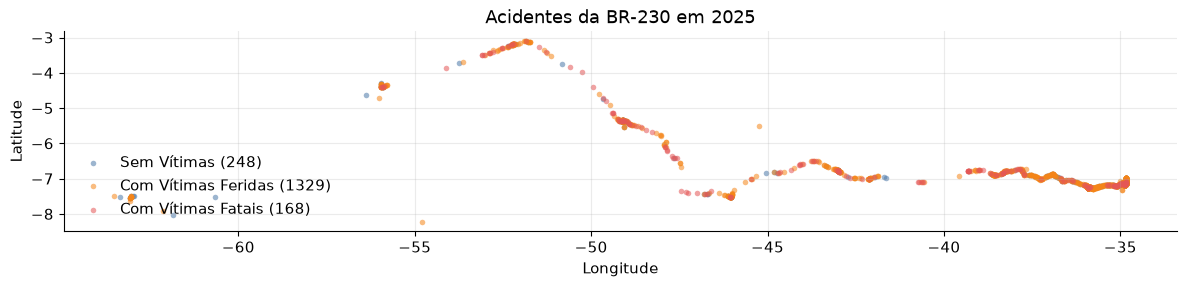

In [16]:
fig, eixo = plt.subplots(figsize=(12, 4.4))
cores = {
    "Sem Vítimas": "#4C78A8",
    "Com Vítimas Feridas": "#F58518",
    "Com Vítimas Fatais": "#E45756",
}
for classe, cor in cores.items():
    parte = br230[br230["classificacao_acidente"].eq(classe)]
    eixo.scatter(
        parte["longitude"],
        parte["latitude"],
        s=16,
        alpha=0.55,
        c=cor,
        label=f"{classe} ({len(parte)})",
        linewidths=0,
    )
eixo.set_xlabel("Longitude")
eixo.set_ylabel("Latitude")
eixo.set_title("Acidentes da BR-230 em 2025")
eixo.legend(frameon=False, loc="lower left")
eixo.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()


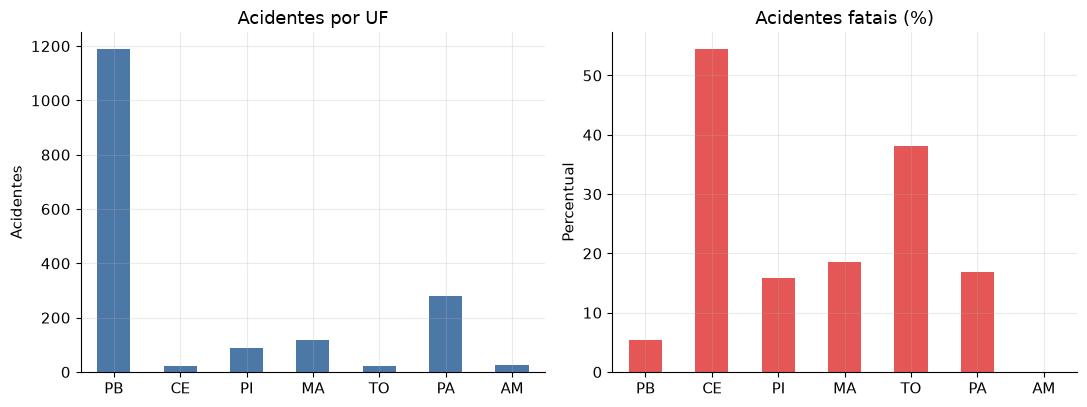

In [17]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
por_uf["acidentes"].plot(kind="bar", ax=eixos[0], color="#4C78A8", rot=0)
eixos[0].set_title("Acidentes por UF")
eixos[0].set_xlabel("")
eixos[0].set_ylabel("Acidentes")

(por_uf["proporcao_fatais"] * 100).plot(kind="bar", ax=eixos[1], color="#E45756", rot=0)
eixos[1].set_title("Acidentes fatais (%)")
eixos[1].set_xlabel("")
eixos[1].set_ylabel("Percentual")
fig.tight_layout()
plt.show()


In [18]:
br230["faixa_km"] = (br230["km"] // 50) * 50
faixas = (
    br230.groupby(["uf", "faixa_km"])
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reset_index()
    .sort_values("acidentes", ascending=False)
)
print("Faixas de 50 km com mais acidentes")
display(faixas.head(12).round(3))

pb = br230[br230["uf"].eq("PB")]
print(
    "Paraíba, km 0 a 50: "
    f"{int((pb['km'] < 50).sum())} acidentes, "
    f"{pb.loc[pb['km'] < 50, 'fatal'].mean():.1%} fatais"
)
print(
    "Paraíba, km 50 em diante: "
    f"{int((pb['km'] >= 50).sum())} acidentes, "
    f"{pb.loc[pb['km'] >= 50, 'fatal'].mean():.1%} fatais"
)


Faixas de 50 km com mais acidentes


,uf,faixa_km,acidentes,proporcao_fatais,mortos
41,PB,0.0,649,0.034,22
23,PA,100.0,132,0.091,12
44,PB,150.0,122,0.041,6
43,PB,100.0,95,0.021,2
42,PB,50.0,92,0.130,14
17,MA,400.0,44,0.068,3
50,PB,450.0,44,0.182,8
47,PB,300.0,39,0.026,1
46,PB,250.0,37,0.054,2
51,PB,500.0,36,0.056,2


Paraíba, km 0 a 50: 649 acidentes, 3.4% fatais
Paraíba, km 50 em diante: 542 acidentes, 7.9% fatais


As coordenadas cobrem o corredor da rodovia, da costa da Paraíba até o sul do Amazonas, e estão preenchidas em todos os 1.745 acidentes do recorte. O volume se acumula no começo da rodovia: João Pessoa, Cabedelo e Campina Grande, e em especial na faixa do km 0 ao km 50 na Paraíba. Essa faixa tem centenas de acidentes e a menor proporção de desfechos fatais do trecho paraibano. No gráfico por estado, a Paraíba lidera a contagem e fica entre as menores proporções de acidentes fatais. Pará, Maranhão, Piauí, Tocantins e Ceará têm menos ocorrências e proporção fatal mais alta. Ceará, Tocantins e Amazonas têm amostras pequenas, então a porcentagem desses três estados descreve o ano de 2025 e ainda sustenta pouco um ranking estável.


### 6.2 Quando os acidentes acontecem

Um dos objetivos do projeto é identificar períodos e horários associados à maior ocorrência. Agregamos mês, dia da semana, hora e fase do dia. Ao lado do volume, calculamos a proporção de acidentes classificados como fatais, porque o horário com mais registros pode diferir do horário com maior gravidade.


In [19]:
ordem_dias = [
    "segunda-feira",
    "terça-feira",
    "quarta-feira",
    "quinta-feira",
    "sexta-feira",
    "sábado",
    "domingo",
]
por_dia = (
    br230.groupby("dia_semana")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reindex(ordem_dias)
)
por_hora = (
    br230.groupby("hora")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reindex(range(24))
)
por_fase = (
    br230.groupby("fase_dia")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .sort_values("acidentes", ascending=False)
)
por_mes = br230.groupby("mes").agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"))

display(por_dia.round(3))
display(por_fase.round(3))


,acidentes,proporcao_fatais,mortos
dia_semana,,,
segunda-feira,241,0.095,32
terça-feira,244,0.066,18
quarta-feira,244,0.094,28
quinta-feira,207,0.082,20
sexta-feira,255,0.071,20
sábado,270,0.100,29
domingo,284,0.155,45


,acidentes,proporcao_fatais,mortos
fase_dia,,,
Pleno dia,941,0.070,74
Plena Noite,634,0.128,87
Anoitecer,103,0.058,7
Amanhecer,67,0.224,24


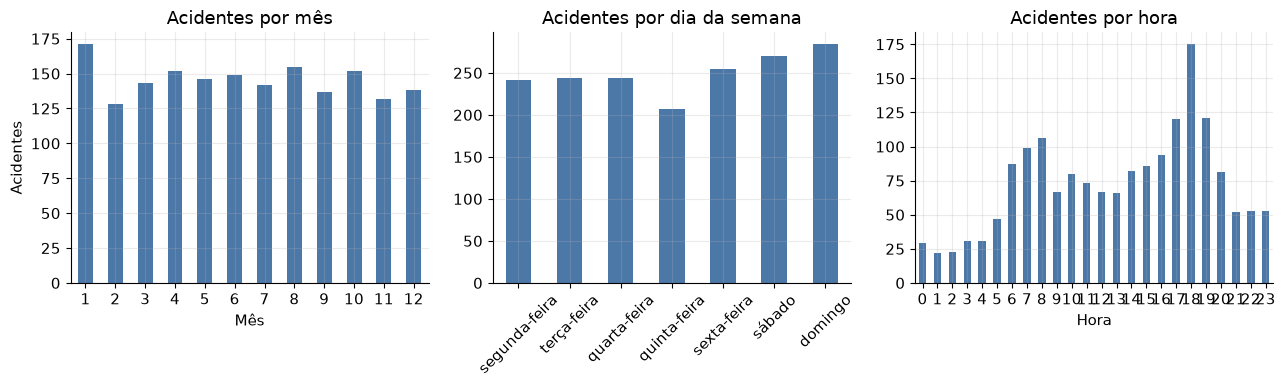

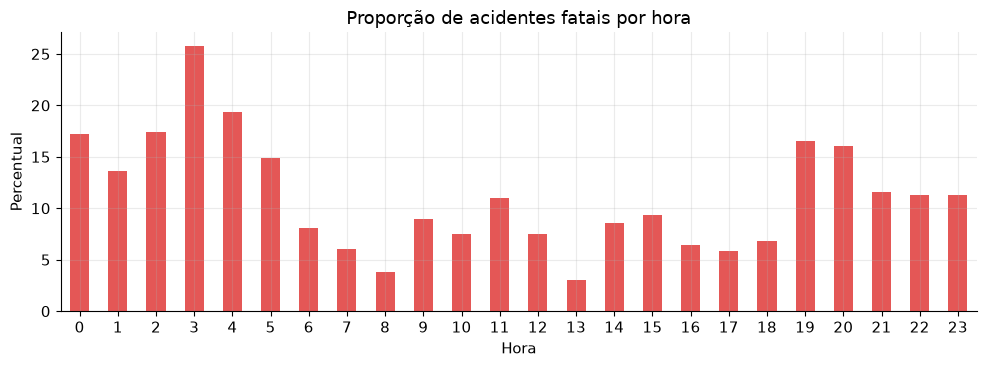

In [20]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 4.0))

por_mes["acidentes"].plot(kind="bar", ax=eixos[0], color="#4C78A8", rot=0)
eixos[0].set_title("Acidentes por mês")
eixos[0].set_xlabel("Mês")
eixos[0].set_ylabel("Acidentes")

por_dia["acidentes"].plot(kind="bar", ax=eixos[1], color="#4C78A8", rot=45)
eixos[1].set_title("Acidentes por dia da semana")
eixos[1].set_xlabel("")
eixos[1].set_ylabel("")

por_hora["acidentes"].plot(kind="bar", ax=eixos[2], color="#4C78A8", rot=0)
eixos[2].set_title("Acidentes por hora")
eixos[2].set_xlabel("Hora")
eixos[2].set_ylabel("")
fig.tight_layout()
plt.show()

fig, eixo = plt.subplots(figsize=(10, 3.8))
(por_hora["proporcao_fatais"] * 100).plot(kind="bar", ax=eixo, color="#E45756", rot=0)
eixo.set_title("Proporção de acidentes fatais por hora")
eixo.set_xlabel("Hora")
eixo.set_ylabel("Percentual")
fig.tight_layout()
plt.show()


O volume mensal da BR-230 oscila sem um mês isolado que domine o ano. O volume diário cresce na sexta, no sábado e no domingo, e o domingo reúne a maior proporção de acidentes fatais. Ao longo do dia, os registros aumentam no fim da tarde e no início da noite, com pico por volta das 18 horas. A proporção fatal é mais alta na madrugada e na fase Amanhecer do que no pleno dia. O horário com mais acidentes registrados e o horário com maior proporção de mortes descrevem fenômenos diferentes.


### 6.3 Condições da via e condição meteorológica

O projeto usa as características da via e a condição meteorológica registrada pela PRF. As tabelas trazem a frequência de cada categoria na BR-230 e a proporção de acidentes fatais em cada uma. A meteorologia é a informada no boletim, no momento da ocorrência. O fluxo de veículos exposto a cada clima fica fora desta base.


In [21]:
def resumo_categoria(coluna):
    tabela = (
        br230.groupby(coluna, dropna=False)
        .agg(acidentes=("id", "size"), mortos=("mortos", "sum"), proporcao_fatais=("fatal", "mean"))
        .sort_values("acidentes", ascending=False)
    )
    tabela["participacao"] = tabela["acidentes"] / tabela["acidentes"].sum()
    return tabela


for coluna in ["condicao_metereologica", "tipo_pista", "uso_solo", "sentido_via"]:
    print(f"\n{coluna}")
    display(resumo_categoria(coluna).round(3))

print("\nTraçado — valores mais frequentes")
display(br230["tracado_via"].value_counts().head(12).rename("acidentes").to_frame())
print(f"Registros com mais de um traçado na mesma célula: {int(br230['tracado_via'].str.contains(';').sum())}")



condicao_metereologica


,acidentes,mortos,proporcao_fatais,participacao
condicao_metereologica,,,,
Céu Claro,1236,120,0.090,0.708
Nublado,171,23,0.117,0.098
Sol,141,24,0.106,0.081
Chuva,116,7,0.060,0.066
Ignorado,39,13,0.282,0.022
Garoa/Chuvisco,36,2,0.056,0.021
Vento,4,2,0.250,0.002
Nevoeiro/Neblina,2,1,0.500,0.001



tipo_pista


,acidentes,mortos,proporcao_fatais,participacao
tipo_pista,,,,
Simples,854,146,0.145,0.489
Dupla,826,42,0.048,0.473
Múltipla,65,4,0.062,0.037



uso_solo


...


sentido_via


,acidentes,mortos,proporcao_fatais,participacao
sentido_via,,,,
Crescente,909,108,0.107,0.521
Decrescente,836,84,0.085,0.479



Traçado — valores mais frequentes


,acidentes
tracado_via,
Reta,934
Curva,131
Reta;Aclive,56
Reta;Declive,53
Aclive;Reta,42
Declive;Reta,40
Reta;Interseção de Vias,40
Interseção de Vias,39
Reta;Em Obras,37


Registros com mais de um traçado na mesma célula: 536


A maior parte dos acidentes da BR-230 em 2025 foi registrada com céu claro, em pista simples ou dupla, com traçado em reta. Pista simples e área rural (`uso_solo = Não`) concentram uma proporção maior de acidentes fatais do que pista dupla e área urbana. Chuva aparece em uma fração menor dos registros e, neste ano, com proporção fatal inferior à do céu claro. Essa comparação descreve os acidentes que a PRF registrou em cada condição. O risco de um veículo se acidentar na chuva depende de quantos veículos circularam sob cada condição, informação que esta base não traz.


### 6.4 Gravidade

Comparamos a contagem de acidentes com a proporção de acidentes fatais, antes de qualquer modelo. Se os dois rankings coincidirem, o mapa de concentração já aponta os trechos de maior gravidade. Se divergirem, os dois resultados precisam aparecer lado a lado.

Em seguida confrontamos essa leitura. A pista simples pode concentrar gravidade porque está fora da Paraíba, e a área rural pode concentrar gravidade porque coincide com pista simples. A tabela cruzada de uso do solo e tipo de pista, no total e fora da Paraíba, testa as duas possibilidades.


In [22]:
gravidade = resumo_categoria("classificacao_acidente")
print(
    f"Acidentes fatais: {int(br230['fatal'].sum())} de {len(br230)} "
    f"({br230['fatal'].mean():.1%}). Mortos: {int(br230['mortos'].sum())}. "
    f"Feridos: {int(br230['feridos'].sum())}."
)
display(gravidade.round(3))


Acidentes fatais: 168 de 1745 (9.6%). Mortos: 192. Feridos: 1995.


,acidentes,mortos,proporcao_fatais,participacao
classificacao_acidente,,,,
Com Vítimas Feridas,1329,0,0.0,0.762
Sem Vítimas,248,0,0.0,0.142
Com Vítimas Fatais,168,192,1.0,0.096


In [23]:
def cruzar(dados):
    tabela = (
        dados.groupby(["uso_solo", "tipo_pista"], dropna=False)
        .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
        .sort_values("acidentes", ascending=False)
    )
    return tabela


print("BR-230 inteira")
display(cruzar(br230).round(3))
print("BR-230 fora da Paraíba")
display(cruzar(br230[br230["uf"].ne("PB")]).round(3))

simples = br230[br230["tipo_pista"].eq("Simples")]
pista_simples = (
    simples.groupby("uf")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reindex(ordem_uf)
)
print("Somente pista simples, por UF")
display(pista_simples.round(3))


BR-230 inteira


,,acidentes,proporcao_fatais,mortos
uso_solo,tipo_pista,,,
Sim,Dupla,576,0.047,27
Não,Simples,495,0.190,114
Sim,Simples,359,0.084,32
Não,Dupla,250,0.052,15
Sim,Múltipla,53,0.038,2
Não,Múltipla,12,0.167,2


BR-230 fora da Paraíba


acidentes  proporcao_fatais  mortos
uso_solo tipo_pista                                     
Não      Simples           291             0.247      85
Sim      Simples           157             0.140      23
         Dupla              96             0.094       9
Não      Dupla               9             0.000       0
Sim      Múltipla            1             0.000       0

Somente pista simples, por UF


,acidentes,proporcao_fatais,mortos
uf,,,
PB,406,0.074,38
CE,19,0.526,11
PI,80,0.162,15
MA,116,0.181,23
TO,21,0.381,9
PA,192,0.219,50
AM,20,0.000,0


Em 2025, 168 dos 1.745 acidentes da BR-230 foram classificados com vítimas fatais (9,6%), com 192 mortos e 1.995 feridos. A contagem e a gravidade desenham dois mapas. O da concentração destaca a Paraíba urbana, em pista dupla, no começo da rodovia. O da gravidade destaca pista simples em área rural, com proporção fatal de 19,0% nesse cruzamento (495 acidentes). Fora da Paraíba, o padrão permanece: a pista simples rural reúne 291 acidentes e proporção fatal de 24,7%. A pista dupla da BR-230 está concentrada na Paraíba e tem proporção fatal baixa. A diferença de gravidade acompanha o tipo de pista, o uso do solo e a mudança de estado. As duas descrições seguem juntas para a fase seguinte.


### 6.5 Causas, tipos, pessoas e veículos

Causa e tipo descrevem a dinâmica registrada no boletim. Pessoa e veículo descrevem quem se feriu. Causa, tipo, estado físico e contagem de vítimas são preenchidos depois da ocorrência. Data, hora, local, fase do dia, meteorologia, pista, traçado e uso do solo descrevem a situação em que o acidente foi registrado.

No histograma de idade, deixamos de fora a idade 0. Na seção de qualidade, esse zero e o ano de fabricação 0 funcionam em grande parte como ausência de informação.


In [24]:
print("Causas principais mais frequentes")
display(br230["causa_acidente"].value_counts().head(12).rename("acidentes").to_frame())
print("Tipos principais mais frequentes")
display(br230["tipo_acidente"].value_counts().head(12).rename("acidentes").to_frame())

causas_por_acidente = expandidos_br.groupby("id")["causa_acidente"].nunique()
tipos_por_acidente = expandidos_br.groupby("id")["tipo_acidente"].nunique()
print(causas_por_acidente.describe().round(2).to_string())
print("\nTipos por acidente")
print(tipos_por_acidente.describe().round(2).to_string())


Causas principais mais frequentes


,acidentes
causa_acidente,
Ausência de reação do condutor,345
Reação tardia ou ineficiente do condutor,232
Acessar a via sem observar a presença dos outros veículos,168
Condutor deixou de manter distância do veículo da frente,128
Ingestão de álcool pelo condutor,101
Manobra de mudança de faixa,91
Transitar na contramão,77
Demais falhas mecânicas ou elétricas,64
Animais na Pista,59


Tipos principais mais frequentes


,acidentes
tipo_acidente,
Colisão traseira,377
Tombamento,234
Colisão transversal,230
Saída de leito carroçável,201
Colisão lateral mesmo sentido,162
Colisão frontal,128
Colisão com objeto,110
Atropelamento de Pedestre,66
Queda de ocupante de veículo,66


count    1745.00
mean        1.74
std         1.21
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        19.00

Tipos por acidente
count    1745.00
mean        2.07
std         0.94
min         1.00
25%         1.00
50%         2.00
75%         3.00
max         6.00


Estado físico


,linhas
estado_fisico,
Ileso,1578
Lesões Leves,1383
Lesões Graves,612
Não Informado,382
NaN,263
Óbito,192


Tipo de envolvido


,linhas
tipo_envolvido,
Condutor,2915
Passageiro,1069
NaN,263
Testemunha,85
Pedestre,76
Cavaleiro,2


Sexo


,linhas
sexo,
Masculino,2840
Feminino,915
Não Informado,382
NaN,263
Ignorado,10


Tipo de veículo


,linhas
tipo_veiculo,
Motocicleta,1321
Automóvel,1271
Caminhonete,422
Semireboque,219
Caminhão,216
Ônibus,178
Caminhão-trator,172
NaN,163
Motoneta,129


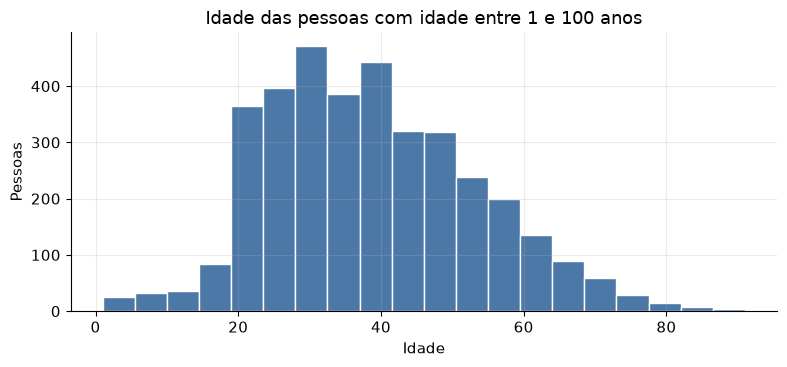

count    3656.0
mean       38.4
std        14.6
min         1.0
25%        27.0
50%        37.0
75%        48.0
max        91.0


In [25]:
pessoas_br = pessoas.loc[pessoas["br"].eq(230)].copy()

print("Estado físico")
display(pessoas_br["estado_fisico"].value_counts(dropna=False).rename("linhas").to_frame())
print("Tipo de envolvido")
display(pessoas_br["tipo_envolvido"].value_counts(dropna=False).rename("linhas").to_frame())
print("Sexo")
display(pessoas_br["sexo"].value_counts(dropna=False).rename("linhas").to_frame())
print("Tipo de veículo")
display(pessoas_br["tipo_veiculo"].value_counts(dropna=False).head(12).rename("linhas").to_frame())

idade_valida = pessoas_br.loc[pessoas_br["idade"].between(1, 100), "idade"]
fig, eixo = plt.subplots(figsize=(8, 3.8))
eixo.hist(idade_valida, bins=20, color="#4C78A8", edgecolor="white")
eixo.set_title("Idade das pessoas com idade entre 1 e 100 anos")
eixo.set_xlabel("Idade")
eixo.set_ylabel("Pessoas")
fig.tight_layout()
plt.show()
print(idade_valida.describe().round(1).to_string())


As causas principais mais registradas são falhas de reação do condutor, acesso à via sem observar os outros veículos, distância em relação ao veículo da frente e ingestão de álcool. Os tipos principais são colisão traseira, tombamento, colisão transversal e saída de leito carroçável. Cerca de 43% dos acidentes da BR-230 têm mais de uma causa no arquivo expandido, e cerca de 66% têm mais de um tipo. O arquivo por ocorrência guarda um par principal; o arquivo expandido guarda o restante.

Entre as pessoas, condutores são a maioria, seguidos de passageiros. Motocicleta e automóvel são os tipos de veículo mais frequentes. A idade informada entre 1 e 100 anos tem mediana de 37 anos. Há um volume relevante de estado físico vazio ou “Não Informado”, que retomamos na qualidade dos dados.


## 7. Qualidade dos dados

Verificamos se a base cobre os casos de que o projeto precisa, quais erros aparecem e como os valores ausentes estão representados. Para cada problema, registramos o encaminhamento na preparação. As conferências da BR-230 tratam do recorte do projeto. As conferências da base nacional tratam da leitura do arquivo.


In [26]:
ausencias_ocorrencia = ocorrencias.isna().sum()
ausencias_ocorrencia = ausencias_ocorrencia[ausencias_ocorrencia.gt(0)].sort_values(ascending=False)

ausencias_pessoa = pessoas.isna().mean().mul(100).round(2)
ausencias_pessoa = ausencias_pessoa[ausencias_pessoa.gt(0)].sort_values(ascending=False)

ausencias_expandido = (nulos_expandidos / linhas_expandidas * 100).round(2)
ausencias_expandido = ausencias_expandido[ausencias_expandido.gt(0)].sort_values(ascending=False)

print("Ausências no arquivo por ocorrência (contagem)")
display(ausencias_ocorrencia.rename("ausencias").to_frame())
print("Ausências no arquivo por pessoa (%)")
display(ausencias_pessoa.rename("percentual").to_frame())
print("Ausências no arquivo expandido (%)")
display(ausencias_expandido.rename("percentual").to_frame())


Ausências no arquivo por ocorrência (contagem)


,ausencias
uop,38
delegacia,22
regional,2
classificacao_acidente,1


Ausências no arquivo por pessoa (%)


,percentual
tipo_envolvido,8.81
estado_fisico,8.81
sexo,8.81
tipo_veiculo,3.26
uop,0.07
delegacia,0.04


Ausências no arquivo expandido (%)


,percentual
idade,18.08
pesid,9.73
tipo_envolvido,9.73
estado_fisico,9.73
sexo,9.73
ilesos,9.73
feridos_leves,9.73
feridos_graves,9.73
mortos,9.73
id_veiculo,3.19


In [27]:
componentes = br230["mortos"] + br230["feridos"] + br230["ilesos"] + br230["ignorados"]
flags = (
    pessoas_br.groupby("id")[["ilesos", "feridos_leves", "feridos_graves", "mortos"]]
    .sum()
    .rename(columns=lambda coluna: f"{coluna}_pessoa")
)
comparacao = br230.set_index("id")[["ilesos", "feridos_leves", "feridos_graves", "mortos", "pessoas"]].join(flags)
linhas_pessoa = pessoas_br.groupby("id").size().rename("linhas_pessoa")
comparacao = comparacao.join(linhas_pessoa)

br230 = br230.copy()
br230["uf_regional"] = br230["regional"].str[-2:]

qualidade = pd.DataFrame(
    [
        {
            "verificacao": "Classificação ausente na BR-230",
            "resultado": int(br230["classificacao_acidente"].isna().sum()),
        },
        {
            "verificacao": "Coordenadas ausentes na BR-230",
            "resultado": int(br230[["latitude", "longitude"]].isna().any(axis=1).sum()),
        },
        {
            "verificacao": "Coordenadas fora do retângulo do Brasil",
            "resultado": int(
                (
                    br230["latitude"].lt(-35)
                    | br230["latitude"].gt(6)
                    | br230["longitude"].lt(-75)
                    | br230["longitude"].gt(-30)
                ).sum()
            ),
        },
        {
            "verificacao": "Acidentes em que mortos + feridos + ilesos + ignorados difere de pessoas",
            "resultado": int(componentes.ne(br230["pessoas"]).sum()),
        },
        {
            "verificacao": "Acidentes em que a soma das flags de ilesos difere da ocorrência",
            "resultado": int(comparacao["ilesos"].ne(comparacao["ilesos_pessoa"]).sum()),
        },
        {
            "verificacao": "Acidentes em que a soma das flags de mortos difere da ocorrência",
            "resultado": int(comparacao["mortos"].ne(comparacao["mortos_pessoa"]).sum()),
        },
        {
            "verificacao": "Acidentes em que a soma das flags de feridos leves difere da ocorrência",
            "resultado": int(comparacao["feridos_leves"].ne(comparacao["feridos_leves_pessoa"]).sum()),
        },
        {
            "verificacao": "Acidentes em que a soma das flags de feridos graves difere da ocorrência",
            "resultado": int(comparacao["feridos_graves"].ne(comparacao["feridos_graves_pessoa"]).sum()),
        },
        {
            "verificacao": "Linhas de pessoa além da coluna pessoas",
            "resultado": int((comparacao["linhas_pessoa"] - comparacao["pessoas"]).sum()),
        },
        {
            "verificacao": "Linhas com pesid = 0 na BR-230",
            "resultado": int(pessoas_br["pesid"].eq(0).sum()),
        },
        {
            "verificacao": "Linhas com idade = 0 na BR-230",
            "resultado": int(pessoas_br["idade"].eq(0).sum()),
        },
        {
            "verificacao": "Linhas com idade acima de 100 anos na BR-230",
            "resultado": int(pessoas_br["idade"].gt(100).sum()),
        },
        {
            "verificacao": "Linhas com ano de fabricação = 0 na BR-230",
            "resultado": int(pessoas_br["ano_fabricacao_veiculo"].eq(0).sum()),
        },
        {
            "verificacao": "UF do acidente diferente da UF no final da regional",
            "resultado": int(br230["uf"].ne(br230["uf_regional"]).sum()),
        },
        {
            "verificacao": "Traçados com mais de um valor",
            "resultado": int(br230["tracado_via"].str.contains(";").sum()),
        },
    ]
)
qualidade


,verificacao,resultado
0,Classificação ausente na BR-230,0
1,Coordenadas ausentes na BR-230,0
2,Coordenadas fora do retângulo do Brasil,0
3,Acidentes em que mortos + feridos + ilesos + i...,65
4,Acidentes em que a soma das flags de ilesos di...,0
5,Acidentes em que a soma das flags de mortos di...,0
6,Acidentes em que a soma das flags de feridos l...,0
7,Acidentes em que a soma das flags de feridos g...,0
8,Linhas de pessoa além da coluna pessoas,113
9,Linhas com pesid = 0 na BR-230,263


In [28]:
print("UF do local × regional do registro")
display(pd.crosstab(br230["uf"], br230["regional"]))
print("Estado físico das linhas com pesid = 0")
display(
    pessoas_br.loc[pessoas_br["pesid"].eq(0), "estado_fisico"]
    .value_counts(dropna=False)
    .rename("linhas")
    .to_frame()
)


UF do local × regional do registro


regional,SPRF-AM,SPRF-CE,SPRF-MA,SPRF-PA,SPRF-PB,SPRF-PI,SPRF-TO
uf,,,,,,,
AM,24,0,0,0,0,0,0
CE,0,20,0,0,2,0,0
MA,0,0,87,0,0,32,0
PA,0,0,0,280,0,0,0
PB,0,0,0,0,1191,0,0
PI,0,0,0,0,0,88,0
TO,0,0,0,0,0,0,21


Estado físico das linhas com pesid = 0


,linhas
estado_fisico,
NaN,263


Na BR-230, latitude, longitude, quilômetro, data e classificação estão preenchidos, e as coordenadas caem dentro do retângulo do Brasil. A soma, por acidente, dos indicadores de ileso, ferido e morto no arquivo por pessoa reproduz as contagens do arquivo por ocorrência.

A preparação fica com os pontos abaixo:

- `pesid = 0` marca pessoa sem identificação (263 linhas na BR-230). O mesmo código se repete e deixa de identificar uma pessoa. Há 113 linhas de pessoa além da coluna `pessoas`; são repetições desse identificador zero dentro do mesmo acidente.
- Idade 0 aparece em 753 linhas e ano de fabricação 0 em 567. Os dois valores misturam informação ausente com o número zero. Há também uma idade de 914 anos.
- Em 65 acidentes da BR-230, a soma de mortos, feridos, ilesos e ignorados difere de `pessoas`. A coluna `pessoas` continua sendo a contagem de referência, porque coincide com as pessoas distintas do outro arquivo.
- Em 34 acidentes, a UF do município difere da UF escrita na regional. O caso mais visível é município no Maranhão com regional do Piauí, na região de divisa. No mapa, a UF e as coordenadas do local prevalecem sobre a unidade administrativa que lavrou o boletim.
- 536 registros trazem traçado composto. Na preparação, separamos esse campo ou reduzimos ao primeiro valor, conforme a análise.
- A classe “Com Vítimas Fatais” representa 9,6% dos acidentes da BR-230. As métricas de classificação dessa classe vão conviver com esse desbalanceamento.
- A pasta contém apenas 2025. Trechos com dezenas de acidentes, em especial no Ceará, no Tocantins e no Amazonas, ficam sensíveis a um único ano.


## 8. Validação com fonte externa

Comparamos os totais da base com o Anuário Estatístico 2025 da PRF, divulgado em maio de 2026. O anuário publica sinistros, mortes e feridos no país e os volumes de algumas rodovias e estados. A segunda referência é a descrição da BR-230 pelo DNIT: rodovia transversal de cerca de 4.260 km implantados, de Cabedelo (PB) a Lábrea (AM), com trecho de cerca de 144,7 km no Tocantins e cerca de 521 km na Paraíba.

A coincidência com o anuário indica que o CSV local é a extração do fechamento de 2025. A extensão por estado mostra que o quilômetro observado permanece dentro do comprimento publicado do trecho.


In [29]:
totais = {
    "Sinistros em 2025": (72_529, len(ocorrencias)),
    "Mortes em 2025": (6_043, int(ocorrencias["mortos"].sum())),
    "Feridos em 2025": (83_550, int(ocorrencias["feridos"].sum())),
    "Sinistros na BR-101": (13_014, int(ocorrencias["br"].eq(101).sum())),
    "Sinistros na BR-116": (11_021, int(ocorrencias["br"].eq(116).sum())),
    "Sinistros na BR-040": (3_502, int(ocorrencias["br"].eq(40).sum())),
    "Sinistros em Minas Gerais": (9_570, int(ocorrencias["uf"].eq("MG").sum())),
    "Sinistros em Santa Catarina": (8_186, int(ocorrencias["uf"].eq("SC").sum())),
    "Sinistros no Paraná": (7_630, int(ocorrencias["uf"].eq("PR").sum())),
}
validacao = pd.DataFrame(
    [{"indicador": nome, "anuario_prf_2025": publicado, "base_local": observado}
     for nome, (publicado, observado) in totais.items()]
)
validacao["confere"] = validacao["anuario_prf_2025"].eq(validacao["base_local"])
validacao


,indicador,anuario_prf_2025,base_local,confere
0,Sinistros em 2025,72529,72529,True
1,Mortes em 2025,6043,6043,True
2,Feridos em 2025,83550,83550,True
3,Sinistros na BR-101,13014,13014,True
4,Sinistros na BR-116,11021,11021,True
5,Sinistros na BR-040,3502,3502,True
6,Sinistros em Minas Gerais,9570,9570,True
7,Sinistros em Santa Catarina,8186,8186,True
8,Sinistros no Paraná,7630,7630,True


In [30]:
extensao_publicada = {"PB": 521.0, "TO": 144.7}
checagem_via = pd.DataFrame(
    [
        {
            "marco": "Estados da BR-230 presentes na base",
            "referencia": "AM, CE, MA, PA, PB, PI, TO",
            "observado": ", ".join(ordem_uf),
            "confere": set(br230["uf"].unique()) == set(ordem_uf),
        },
        {
            "marco": "Km máximo na Paraíba, frente aos 521 km do trecho",
            "referencia": "até 521 km",
            "observado": f"{br230.loc[br230['uf'].eq('PB'), 'km'].max():.1f} km",
            "confere": bool(br230.loc[br230["uf"].eq("PB"), "km"].max() <= extensao_publicada["PB"]),
        },
        {
            "marco": "Km máximo no Tocantins, frente aos 144,7 km do trecho",
            "referencia": "até 144,7 km",
            "observado": f"{br230.loc[br230['uf'].eq('TO'), 'km'].max():.1f} km",
            "confere": bool(br230.loc[br230["uf"].eq("TO"), "km"].max() <= extensao_publicada["TO"]),
        },
        {
            "marco": "Período coberto",
            "referencia": "2025-01-01 a 2025-12-31",
            "observado": f"{ocorrencias['data_inversa'].min()} a {ocorrencias['data_inversa'].max()}",
            "confere": ocorrencias["data_inversa"].min() == "2025-01-01"
            and ocorrencias["data_inversa"].max() == "2025-12-31",
        },
    ]
)
checagem_via


,marco,referencia,observado,confere
0,Estados da BR-230 presentes na base,"AM, CE, MA, PA, PB, PI, TO","PB, CE, PI, MA, TO, PA, AM",True
1,"Km máximo na Paraíba, frente aos 521 km do trecho",até 521 km,516.0 km,True
2,"Km máximo no Tocantins, frente aos 144,7 km do...","até 144,7 km",144.0 km,True
3,Período coberto,2025-01-01 a 2025-12-31,2025-01-01 a 2025-12-31,True


Os nove totais publicados no anuário — sinistros, mortes, feridos, BR-101, BR-116, BR-040, Minas Gerais, Santa Catarina e Paraná — coincidem com a soma do arquivo local. O recorte da BR-230 aparece nos sete estados da rodovia. O maior quilômetro observado na Paraíba (516) fica dentro dos 521 km do trecho, e o do Tocantins (144) fica dentro dos 144,7 km publicados pelo DNIT. O arquivo usado aqui é o fechamento de 2025 da PRF, e o filtro `br == 230` corresponde à rodovia do projeto.

Municípios do traçado oficial, como Lábrea, no extremo oeste, ficam sem acidente neste arquivo em 2025. A ausência de ponto no mapa indica ausência de registro naquele ano. A segurança desses segmentos depende do movimento de veículos, que esta base não contém.


## 9. Síntese e encaminhamentos

Fechamos a exploração com o que os dados respondem, com o que ainda falta e com o modo como a pergunta se reparte.

**A parte espacial está coberta.** Há 1.745 acidentes da BR-230 em 2025, com latitude e longitude preenchidas, no corredor entre a Paraíba e o Amazonas. Localizamos a concentração histórica e construímos o mapa a partir do arquivo por ocorrência.

**Concentração e gravidade pedem duas leituras.** O volume se acumula na Paraíba urbana, sobretudo entre o km 0 e o km 50. A proporção de acidentes fatais é mais alta em pista simples e em área rural, e o padrão permanece quando a Paraíba sai da conta. Domingo, madrugada e amanhecer também elevam essa proporção em relação ao pleno dia.

**A base registra acidentes já ocorridos.** Cada linha é uma ocorrência consumada. Fluxo, extensão percorrida e trechos-hora sem acidente ficam de fora. Com esta fonte, descrevemos onde os acidentes registrados se acumulam e quais condições aparecem nos acidentes mais graves. Estimar a probabilidade de um acidente ocorrer em um trecho pede uma fonte de exposição, como o volume de tráfego do DNIT, ou uma malha de segmentos que inclua os trechos sem ocorrência.

**O desfecho disponível para o componente preditivo é a gravidade do acidente.** A classificação “Com Vítimas Fatais” está preenchida, coincide com `mortos > 0` neste recorte e representa 9,6% das ocorrências. Causa, tipo e estado físico descrevem o acidente depois que ele ocorreu. O contexto anterior ao desfecho, dentro desta base, está em data, hora, local, fase do dia, meteorologia, pista, traçado e uso do solo.

**O ano é único e faltam denominadores.** Ceará, Tocantins e Amazonas ficam com poucas dezenas de casos. A contingência já prevista na fase de negócio — ampliar o período quando um trecho tiver poucos registros — continua válida. A preparação segue com 2025 para o mapa e para o perfil de gravidade, e a modelagem explicita que a classe fatal é minoritária.

### Decisões para a preparação dos dados

| Decisão | Motivo |
| --- | --- |
| Contar acidentes e desenhar o mapa com `datatran2025.csv` | Uma linha por acidente e coordenadas completas |
| Usar `acidentes2025.csv` para pessoas e veículos | O grão é a pessoa; as flags 0/1, somadas por `id`, recuperam a ocorrência |
| Usar o arquivo expandido só para causas e tipos adicionais | Sem filtrar causa principal e ordem 1, o mesmo acidente é contado várias vezes |
| Posicionar pelo par latitude/longitude | O km recomeça em cada UF |
| Tratar `pesid = 0`, idade 0 e ano de fabricação 0 como ausência | São códigos de preenchimento, com o número zero no lugar da medida |
| Separar `tracado_via` quando houver ponto e vírgula | 536 registros da BR-230 trazem traçado composto |
| Manter a UF e as coordenadas do município como local do acidente | Em 34 casos a regional administrativa é de outro estado |
| Tratar a classe fatal como desfecho desbalanceado | 168 acidentes em 1.745 |
| Buscar série de outros anos e uma medida de tráfego antes de estimar probabilidade de ocorrência | 2025 traz o registro dos acidentes, sem exposição e sem histórico longo |


### Referências

- Chapman, P. et al. *CRISP-DM 1.0*. Tarefas de entendimento dos dados.
- Polícia Rodoviária Federal. Dados abertos de acidentes. <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf>
- Polícia Rodoviária Federal. Dicionário de dados de acidentes. <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes>
- Polícia Rodoviária Federal. Anuário Estatístico 2025. <https://www.gov.br/prf/pt-br/noticias/nacionais/2026/maio/prf-divulga-anuario-estatistico-de-2025-com-aumento-de-infracoes-e-reducao-de-mortes-nas-rodovias-federais>
- DNIT. Restauração na BR-230/TO, com a extensão do trecho tocantinense e a extensão implantada da rodovia. <https://www.gov.br/dnit/pt-br/noticias-periodo-eleitoral/restauracao-de-33-30-quilometros-e-concluida-na-br-230-no-tocantins>
